## Creando una RBM para los dígitos de sklearn

Imágenes de 8×8 píxeles de `load_digits` (no es MNIST, que tiene imágenes de 28×28). Este notebook usa `RBM.py`; `digits.ipynb` es una versión más completa del mismo ejemplo.

In [1]:
import matplotlib.pyplot as plt
from sklearn import datasets
import numpy as np

### Conjunto de datos

Data shape: (1797, 8, 8), Target shape: (1797,)


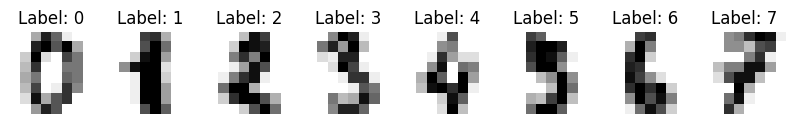

In [2]:
digits = datasets.load_digits()

def drawDataSet(X, y):
    _, axes = plt.subplots(nrows=1, ncols=8, figsize=(10, 3))
    for ax, image, label in zip(axes, X, y):
        ax.set_axis_off()
        ax.imshow(image, cmap=plt.cm.gray_r, interpolation="nearest")
        ax.set_title("Label: %i" % label)
        
print(f'Data shape: {digits.images.shape}, Target shape: {digits.target.shape}')
drawDataSet(digits.images, digits.target)

### Transformando los datos

In [3]:
X , y = digits.images, digits.target

X = X.reshape((-1,64))
print(X.shape)

# Los pixeles de load_digits van de 0 a 16 (no de 0 a 255): se dividen entre 16 para dejarlos en [0, 1]
X = X / 16.0
print(f'Rango de los pixeles: [{X.min()}, {X.max()}]')

(1797, 64)
Rango de los pixeles: [0.0, 1.0]


### Particionado de datos

X_train shape: (1347, 64), X_test shape: (450, 64)


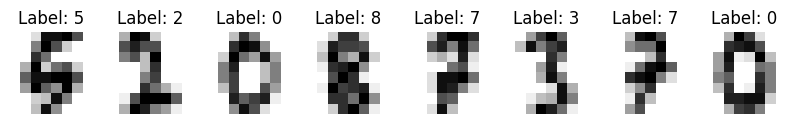

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print(f'X_train shape: {X_train.shape}, X_test shape: {X_test.shape}')
drawDataSet(X_train.reshape((-1,8,8)), y_train)

In [5]:
from RBM import RBM, l2_cost

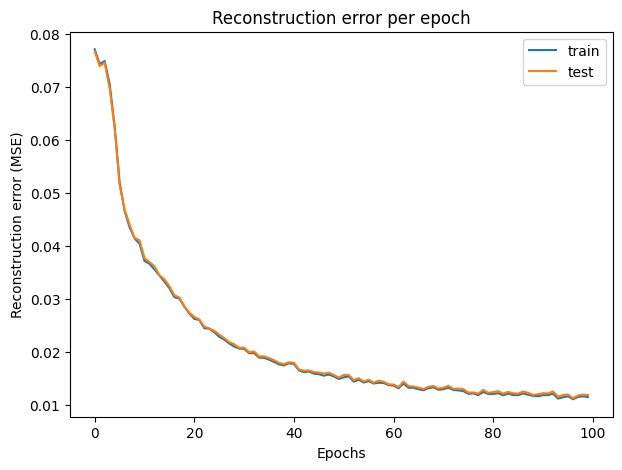

In [6]:
net = RBM(64, 50, seed=0)
history = net.train(X_train, lr=0.1, epochs=100, validation_data=X_test)

## showing stats
def plot(history):
    plt.figure(figsize=(7, 5))
    plt.title('Reconstruction error per epoch')
    plt.xlabel("Epochs")
    plt.ylabel("Reconstruction error (MSE)")
    plt.plot(history['reconstruction_error'], label='train')
    plt.plot(history['val_reconstruction_error'], label='test')
    plt.legend()
    
plot(history)

Error de reconstruccion en prueba: 0.01181 (referencia: 0.07291)


Text(0.5, 0.98, 'RBM')

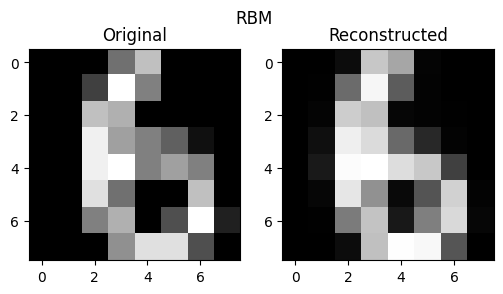

In [7]:
#Testing the network
reconstructed = net.reconstruct(X_test)

# Referencia: reconstruir toda imagen como la imagen media del entrenamiento
baseline = l2_cost(X_train.mean(axis=0), X_test)
print(f'Error de reconstruccion en prueba: {l2_cost(reconstructed, X_test):.5f} (referencia: {baseline:.5f})')

fig, (vax, hax) = plt.subplots(1, 2, figsize=(6, 3))
vax.imshow(X_test.reshape((-1,8,8))[0], cmap='gray')
vax.set_title('Original')
hax.imshow(reconstructed.reshape((-1,8,8))[0], cmap='gray')
hax.set_title('Reconstructed')
plt.suptitle('RBM')